# Selected quantum algorithms in Qiskit

Bell state, Deutsch-Jozsa, Bernstein-Vazirani and Grover's search - each drawn, run on the ideal simulator and on a noise model of IBM Torino. The point for the research questions: *the same algorithm that is perfect in simulation degrades as transpiled depth grows on NISQ hardware.*

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
sys.path.insert(0, str(ROOT / 'algorithms'))
from quantum_algorithms import *
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

## Bell state - superposition + entanglement

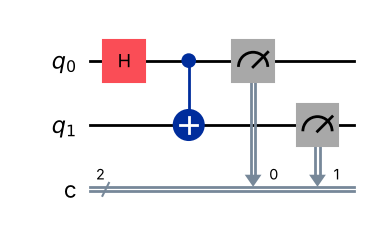

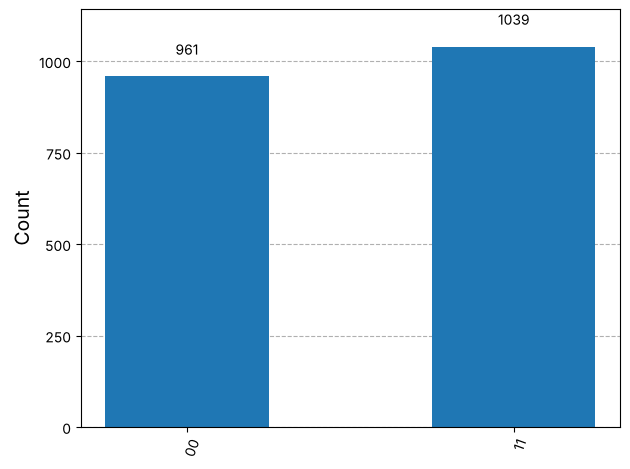

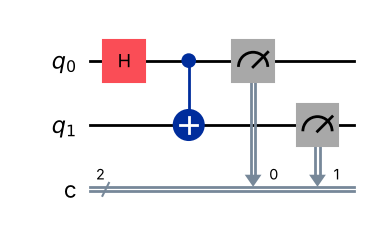

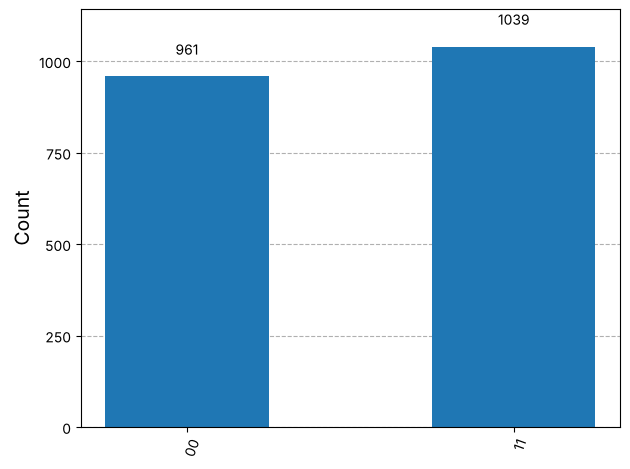

In [2]:
qc = bell_state(); display(qc.draw('mpl'))
plot_histogram(AerSimulator().run(qc, shots=2000, seed_simulator=1).result().get_counts())

## Deutsch-Jozsa - constant or balanced in one query

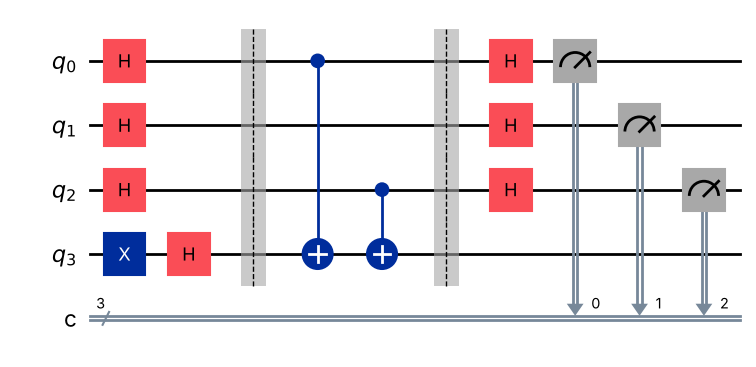

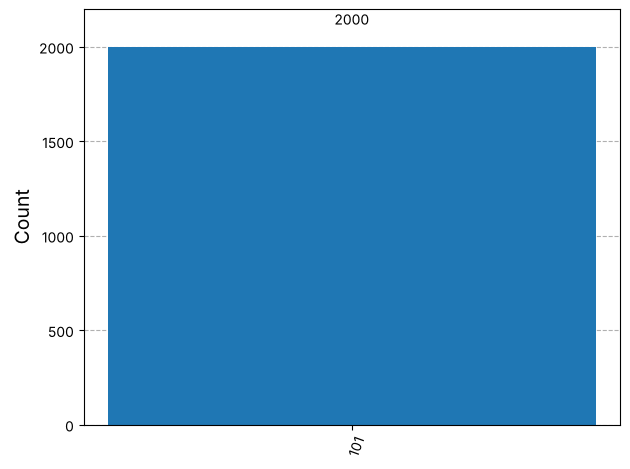

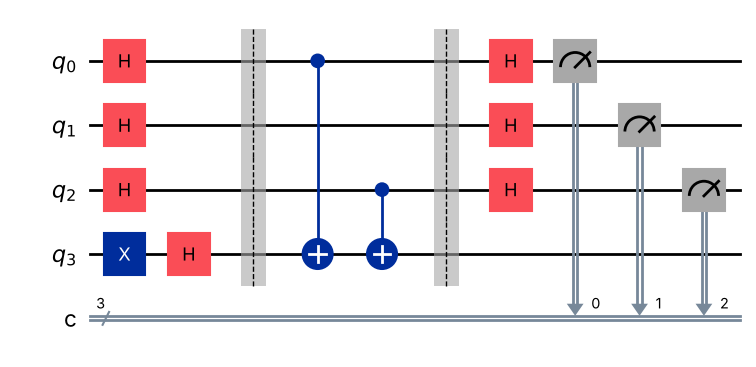

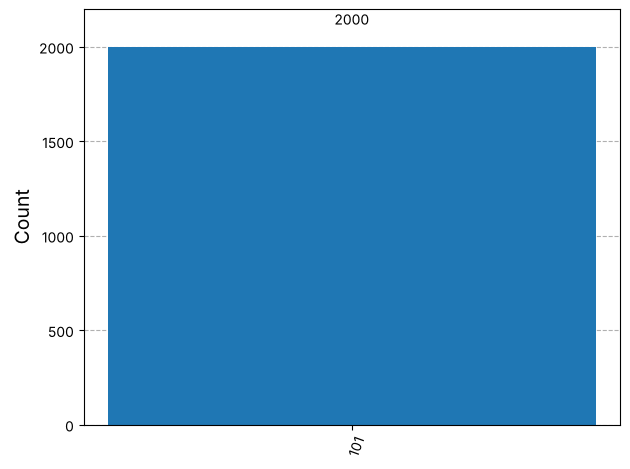

In [3]:
qc = deutsch_jozsa(3, True, '101'); display(qc.draw('mpl'))
plot_histogram(AerSimulator().run(qc, shots=2000, seed_simulator=1).result().get_counts())

## Bernstein-Vazirani - recover a hidden string in one query

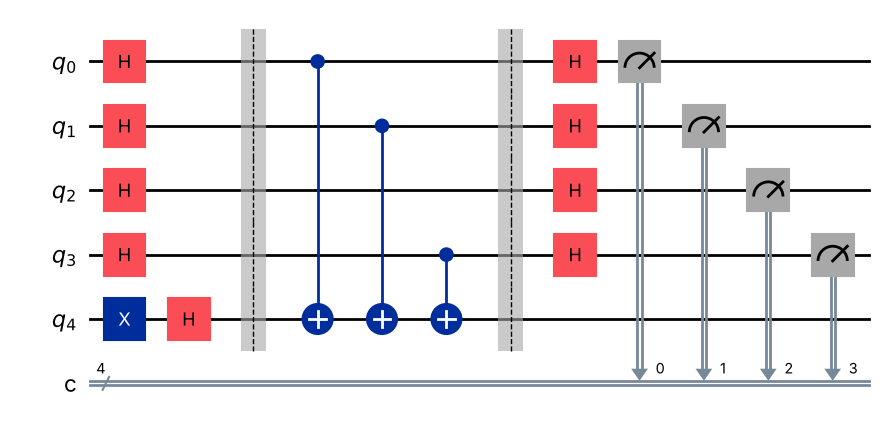

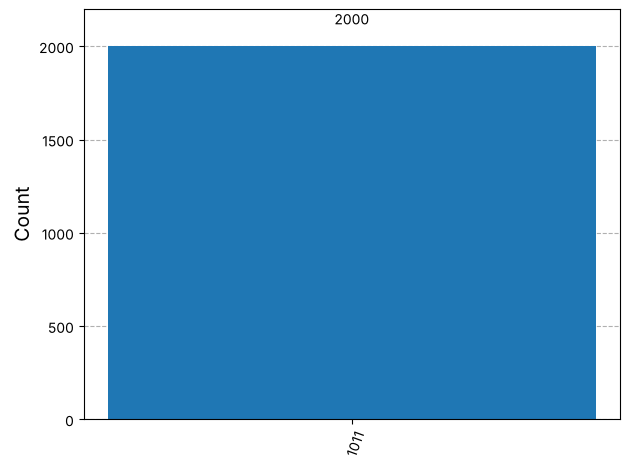

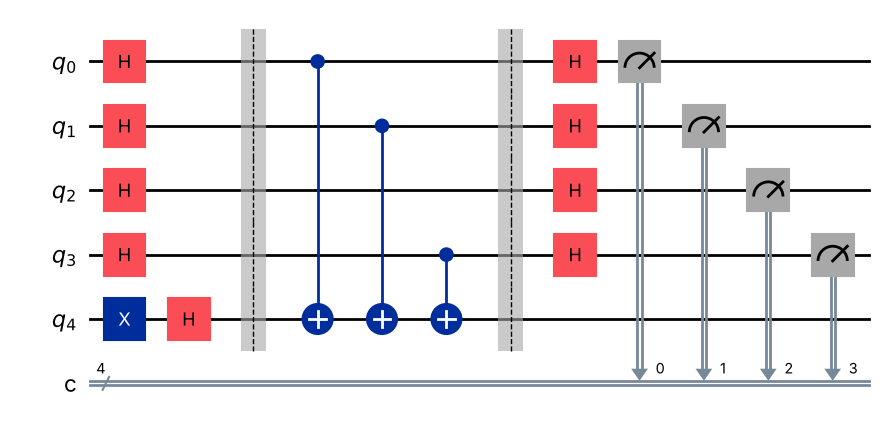

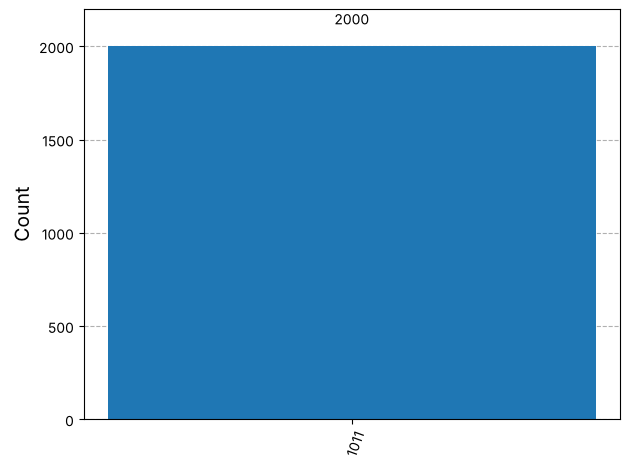

In [4]:
qc = bernstein_vazirani('1011'); display(qc.draw('mpl'))
plot_histogram(AerSimulator().run(qc, shots=2000, seed_simulator=1).result().get_counts())

## Grover's search - amplitude amplification

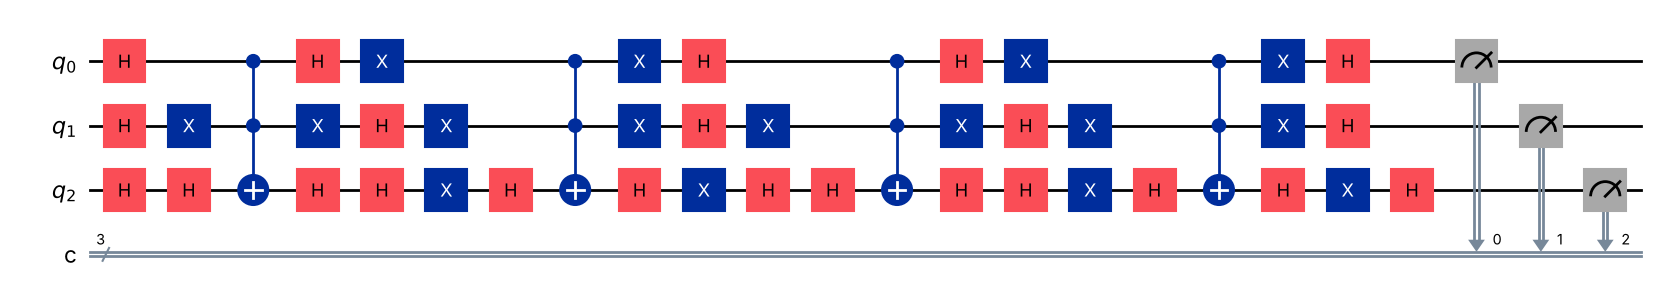

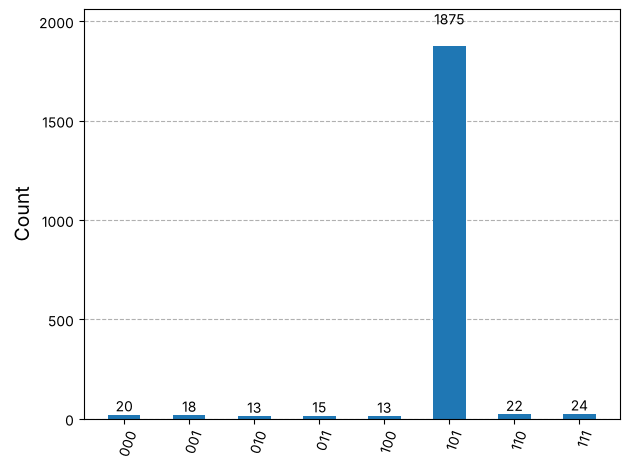

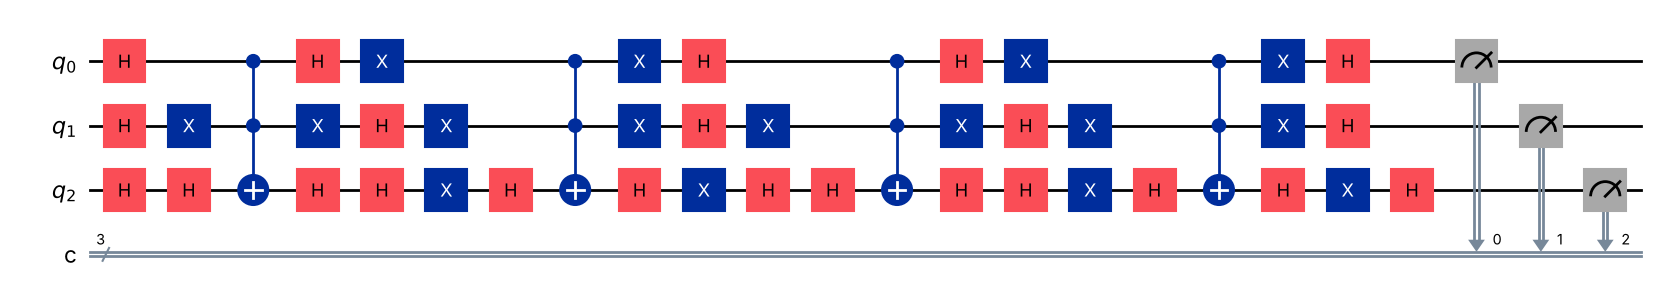

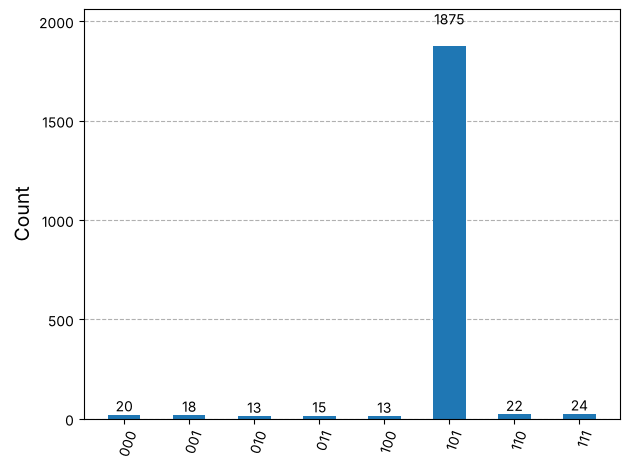

In [5]:
qc = grover('101'); display(qc.draw('mpl', fold=-1))
plot_histogram(AerSimulator().run(transpile(qc, AerSimulator()), shots=2000, seed_simulator=1).result().get_counts())

## Ideal vs. noisy hardware, all algorithms

In [6]:
rows = run_all('fake_torino')
pd.DataFrame(rows).drop(columns=['top_ideal', 'top_noisy'])

,algorithm,qubits,logical_depth,hardware_depth,hardware_2q_gates,success_ideal,success_noisy,classical_queries_worst,quantum_queries
0,Bell state,2,3,7,1,1.000000,0.982422,NaN,NaN
1,Deutsch-Jozsa n=3 (balanced),4,6,14,2,1.000000,0.998535,5.0,1.0
2,Deutsch-Jozsa n=3 (constant),4,4,7,0,1.000000,0.981201,5.0,1.0
3,Bernstein-Vazirani s=1011,5,7,15,3,1.000000,0.958496,4.0,1.0
4,Grover n=2 (find 11),2,12,10,2,1.000000,0.974609,3.0,1.0
5,Grover n=3 (find 101),3,22,134,37,0.943848,0.799561,7.0,2.0
6,Grover n=4 (find 0110),4,38,504,161,0.958496,0.510498,15.0,3.0
